# 01 · Data audit (pipeline steps 1 and 2)

**Question:** what is really in the Touché sword-strike recordings?

Before using the data, we check the things the rest of the pipeline depends on: the units, which axis points up, the time steps,
the rotations, and the grip and gesture columns. Nothing is changed here, we only look.

**Input:** the raw recording files in `data/raw/`. **Output:** the figures `audit_*.png` in `reports/figures/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from strikefit_ml.data_audit import axis_summary, file_summary, frame_evidence, quaternion_norm_deviation, run_checks
from strikefit_ml.ingestion import ENTITIES, list_recordings, load_config, load_recording, recording_stem, resolve

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
cfg = load_config()
figures = resolve(cfg, "figures_dir")
figures.mkdir(parents=True, exist_ok=True)

## Step 1: load the recordings
`load_recording` reads one file and checks that all columns are there, are numeric, have no missing values, and that time only moves forward.

In [2]:
files = list_recordings(resolve(cfg, "raw_dir"))
recordings = {recording_stem(f): load_recording(f) for f in files}
rows = sum(len(d) for d in recordings.values())
minutes = sum(d.Time.iloc[-1] for d in recordings.values()) / 60
print(f"{len(files)} recordings, {rows:,} rows, {minutes:.1f} minutes in total")
print("columns:", list(next(iter(recordings.values())).columns))

8 recordings, 64,965 rows, 12.1 minutes in total
columns: ['Time', 'Head_x', 'Head_y', 'Head_z', 'Head_rotw', 'Head_rotx', 'Head_roty', 'Head_rotz', 'ControllingHand_x', 'ControllingHand_y', 'ControllingHand_z', 'ControllingHand_rotw', 'ControllingHand_rotx', 'ControllingHand_roty', 'ControllingHand_rotz', 'SecondaryHand_x', 'SecondaryHand_y', 'SecondaryHand_z', 'SecondaryHand_rotw', 'SecondaryHand_rotx', 'SecondaryHand_roty', 'SecondaryHand_rotz', 'Grip', 'Gesture']


## Step 2: check the data
### 2.1 Size, length and time steps of every recording

In [3]:
gap_limit = cfg["data"]["max_gap_s"]
overview = pd.DataFrame([file_summary(f, recordings[recording_stem(f)], gap_limit) for f in files]).set_index("file")
overview

,rows,duration_s,first_time_s,dt_median_ms,dt_p95_ms,dt_max_ms,gaps_over_limit,longest_gap_s
file,,,,,,,,
capture_20170811093232391,7630,85.215,0.000,11.169,11.772,21.919,0,0.022
capture_20170811093351273,7054,78.872,0.000,11.169,11.825,109.161,1,0.109
capture_20170811093544021,10082,112.737,0.000,11.169,11.840,160.004,1,0.160
capture_20170811093649846,5882,65.813,0.000,11.169,11.780,150.360,1,0.150
capture_20170811093813954,7524,84.097,0.000,11.169,11.780,91.156,0,0.091
capture_20170811093916024,6847,76.554,0.000,11.169,11.802,116.089,1,0.116
capture_20170811094419924,10726,119.798,0.000,11.165,11.757,21.954,0,0.022
capture_20170811094603111,9220,103.110,0.000,11.169,11.795,161.362,1,0.161


In [4]:
steps_ms = np.concatenate([np.diff(d.Time) for d in recordings.values()]) * 1000
print(f"time step: median {np.median(steps_ms):.1f} ms, 95th percentile {np.percentile(steps_ms, 95):.1f} ms, largest {steps_ms.max():.0f} ms")
print(f"so the recordings were made at about {1000 / np.median(steps_ms):.0f} Hz")

jumps = [(name, int(i), float(np.diff(d.Time)[i])) for name, d in recordings.items() for i in np.flatnonzero(np.diff(d.Time) > gap_limit)]
print(f"\ntime jumps larger than {gap_limit * 1000:.0f} ms:")
pd.DataFrame(jumps, columns=["recording", "row_before_jump", "jump_s"])

time step: median 11.2 ms, 95th percentile 11.8 ms, largest 161 ms
so the recordings were made at about 90 Hz

time jumps larger than 100 ms:


,recording,row_before_jump,jump_s
0,capture_20170811093351273,0,0.109
1,capture_20170811093544021,0,0.160
2,capture_20170811093649846,0,0.150
3,capture_20170811093916024,0,0.116
4,capture_20170811094603111,0,0.161


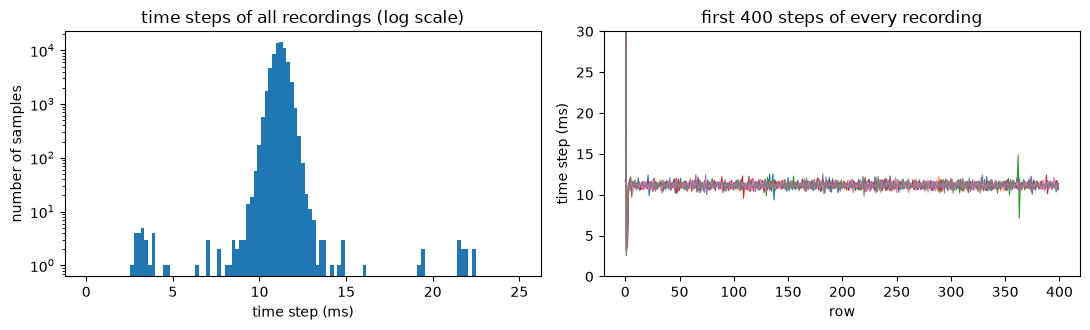

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(steps_ms, bins=np.linspace(0, 25, 120))
ax[0].set_yscale("log")
ax[0].set_xlabel("time step (ms)")
ax[0].set_ylabel("number of samples")
ax[0].set_title("time steps of all recordings (log scale)")
for d in recordings.values():
    ax[1].plot(np.diff(d.Time)[:400] * 1000, lw=0.8)
ax[1].set_ylim(0, 30)
ax[1].set_xlabel("row")
ax[1].set_ylabel("time step (ms)")
ax[1].set_title("first 400 steps of every recording")
fig.tight_layout()
fig.savefig(figures / "audit_timesteps.png", dpi=130)
plt.show()

### 2.2 Units and axes
If the numbers are centimetres and z points up, the head of a standing person should be at a z of about 150 to 190.

In [6]:
pooled = pd.concat(recordings.values(), ignore_index=True)
axis_summary(pooled)

,min,max,mean
Head_x,-79.980,153.353,-44.678
Head_y,-48.111,80.148,-7.045
Head_z,113.753,163.483,153.265
ControllingHand_x,-122.480,103.144,-41.195
ControllingHand_y,-79.424,132.550,3.564
ControllingHand_z,36.608,199.849,111.741
SecondaryHand_x,-138.587,146.481,-55.907
SecondaryHand_y,-111.362,72.567,-24.251
SecondaryHand_z,32.011,204.101,89.551


Head_z: median 154.8, from 113.8 to 163.5, standard deviation 6.0
Head x and y standard deviations: [16.6, 12.3]
controlling-hand speed if centimetres: median 1.96 m/s, 95th percentile 5.71, 99th 7.18


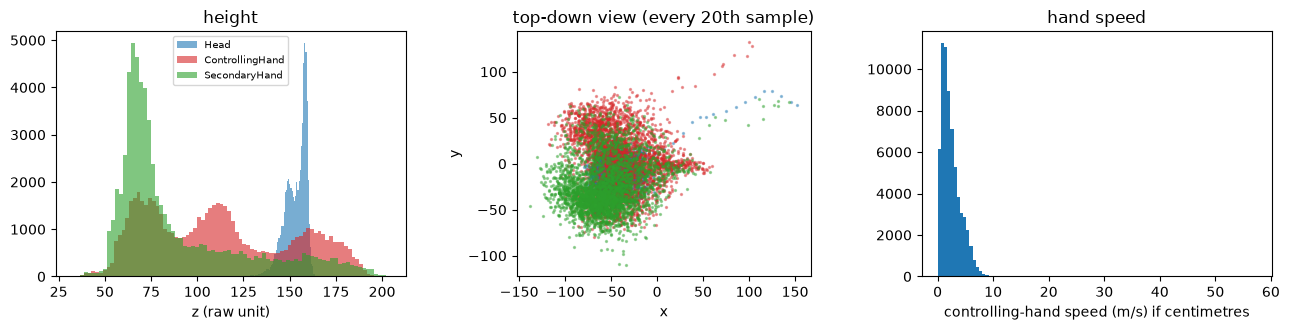

In [7]:
head_z = pooled["Head_z"]
print(f"Head_z: median {head_z.median():.1f}, from {head_z.min():.1f} to {head_z.max():.1f}, standard deviation {head_z.std():.1f}")
print("Head x and y standard deviations:", pooled[["Head_x", "Head_y"]].std().round(1).tolist())

# Hand speed if the unit is centimetres. A sword strike should be a few metres per second.
speeds = []
for d in recordings.values():
    dt = np.diff(d.Time.to_numpy())
    move = np.diff(d[["ControllingHand_x", "ControllingHand_y", "ControllingHand_z"]].to_numpy(), axis=0)
    ok = dt <= gap_limit
    speeds.append(np.linalg.norm(move[ok], axis=1) / dt[ok] / 100)  # cm per second -> m per second
speeds = np.concatenate(speeds)
print(f"controlling-hand speed if centimetres: median {np.median(speeds):.2f} m/s, 95th percentile {np.percentile(speeds, 95):.2f}, 99th {np.percentile(speeds, 99):.2f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for name, colour in (("Head", "tab:blue"), ("ControllingHand", "tab:red"), ("SecondaryHand", "tab:green")):
    ax[0].hist(pooled[f"{name}_z"], bins=80, alpha=0.6, color=colour, label=name)
    ax[1].scatter(pooled[f"{name}_x"][::20], pooled[f"{name}_y"][::20], s=2, alpha=0.4, color=colour, label=name)
ax[0].set_xlabel("z (raw unit)")
ax[0].set_title("height")
ax[0].legend(fontsize=7)
ax[1].set_xlabel("x")
ax[1].set_ylabel("y")
ax[1].set_aspect("equal")
ax[1].set_title("top-down view (every 20th sample)")
ax[2].hist(speeds, bins=100)
ax[2].set_xlabel("controlling-hand speed (m/s) if centimetres")
ax[2].set_title("hand speed")
fig.tight_layout()
fig.savefig(figures / "audit_axes.png", dpi=130)
plt.show()

### 2.3 Rotations, grip and gesture

In [8]:
deviation = pd.DataFrame({name: quaternion_norm_deviation(d) for name, d in recordings.items()}).T
print("largest distance of a quaternion's length from 1 (0 means perfect):")
display(deviation)

negative_w = pd.DataFrame({e: {name: float((d[f"{e}_rotw"] < 0).mean()) for name, d in recordings.items()} for e in ENTITIES})
print("share of rows where w is negative (q and -q are the same rotation, so SLERP in step 3 must treat them as one):")
display(negative_w)

largest distance of a quaternion's length from 1 (0 means perfect):


,Head,ControllingHand,SecondaryHand
capture_20170811093232391,0.000,0.000,0.000
capture_20170811093351273,0.000,0.000,0.000
capture_20170811093544021,0.000,0.000,0.000
capture_20170811093649846,0.000,0.000,0.000
capture_20170811093813954,0.000,0.000,0.000
capture_20170811093916024,0.000,0.000,0.000
capture_20170811094419924,0.000,0.000,0.000
capture_20170811094603111,0.000,0.000,0.000


share of rows where w is negative (q and -q are the same rotation, so SLERP in step 3 must treat them as one):


,Head,ControllingHand,SecondaryHand
capture_20170811093232391,1.000,0.075,0.025
capture_20170811093351273,1.000,0.044,0.023
capture_20170811093544021,1.000,0.050,0.016
capture_20170811093649846,1.000,0.045,0.022
capture_20170811093813954,1.000,0.052,0.035
capture_20170811093916024,1.000,0.071,0.016
capture_20170811094419924,1.000,0.046,0.037
capture_20170811094603111,1.000,0.062,0.062


Grip values in all recordings: [1] (always the same, so it carries no information here)


,rows
Gesture,
#NONE#,41358
strike_left,3125
strike_upright,2860
strike_up,2784
strike_upleft,2645
strike_right,2587
strike_front,2543
strike_down,2456
strike_downright,2346


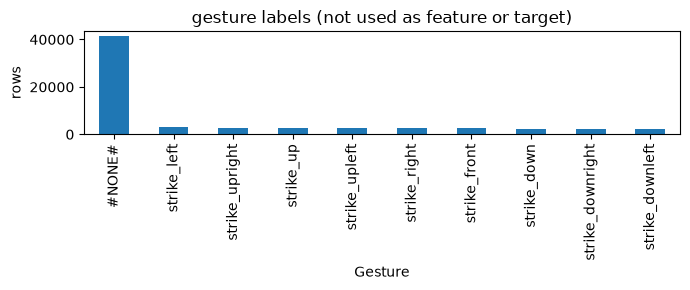

In [9]:
print("Grip values in all recordings:", sorted(pooled.Grip.unique().tolist()), "(always the same, so it carries no information here)")
gestures = pooled.Gesture.value_counts()
display(gestures.to_frame("rows"))
ax = gestures.plot.bar(figsize=(7, 3), color="tab:blue")
ax.set_ylabel("rows")
ax.set_title("gesture labels (not used as feature or target)")
plt.tight_layout()
plt.savefig(figures / "audit_gestures.png", dpi=130)
plt.show()

### 2.4 Which way is up, forward and right?
The head rotates only a little (see `head_tilt_deg` and `head_yaw_std_deg`) and the players all face about the same way,
so the world axes can be read from where the hands are. These numbers are hints for the Unity axis mapping, not proof.

In [10]:
evidence = frame_evidence(list(recordings.values()))
evidence.index = list(recordings)
evidence

,head_tilt_deg,head_yaw_mean_deg,head_yaw_std_deg,ch_offset_x_cm,ch_offset_y_cm,sh_offset_x_cm,sh_offset_y_cm,ch_reach_dir_deg,sh_reach_dir_deg,head_motion_axis_deg,head_motion_axis_share
capture_20170811093232391,8.673,1.576,7.321,0.431,10.288,-7.862,-17.199,95.896,-138.953,18.862,0.548
capture_20170811093351273,11.299,0.596,9.723,0.050,6.512,-9.060,-15.720,122.036,-154.171,8.907,0.616
capture_20170811093544021,12.074,3.834,9.827,1.380,9.676,-10.391,-17.693,94.363,-155.178,163.258,0.729
capture_20170811093649846,12.004,5.470,10.217,4.677,11.672,-10.723,-17.566,91.096,-149.623,173.477,0.668
capture_20170811093813954,14.504,7.446,10.758,2.405,11.672,-9.779,-16.572,101.695,-156.834,28.077,0.521
capture_20170811093916024,14.163,5.440,9.294,3.951,11.444,-15.671,-20.563,83.192,-145.126,151.778,0.692
capture_20170811094419924,10.399,0.693,10.296,8.635,12.325,-13.879,-18.398,68.143,-156.260,62.196,0.578
capture_20170811094603111,12.454,3.943,11.990,4.712,10.873,-11.714,-14.219,85.321,-154.519,28.107,0.911


average over recordings:


,head_tilt_deg,head_yaw_mean_deg,head_yaw_std_deg,ch_offset_x_cm,ch_offset_y_cm,sh_offset_x_cm,sh_offset_y_cm,ch_reach_dir_deg,sh_reach_dir_deg,head_motion_axis_deg,head_motion_axis_share
mean,11.946,3.625,9.928,3.280,10.558,-11.135,-17.241,92.718,-151.333,79.333,0.658


The controlling (sword) hand is farthest from the head at about 93 degrees from +x towards +y. A value of 90 would mean that +y is exactly forward.


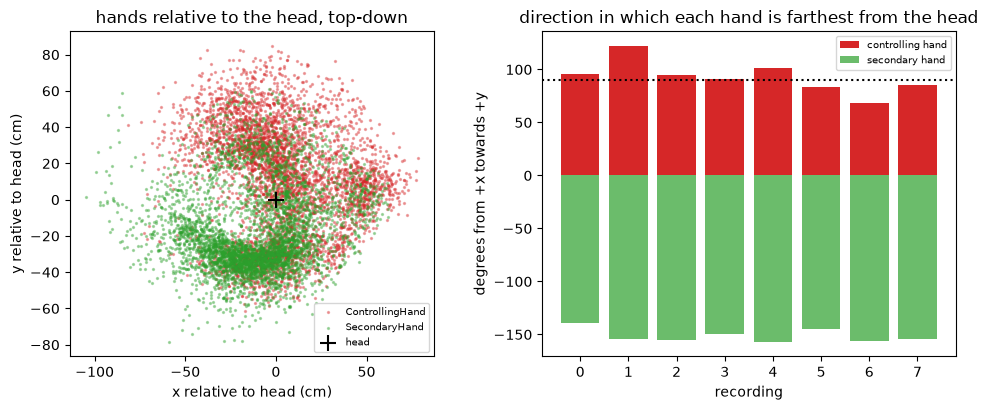

In [11]:
print("average over recordings:")
display(evidence.mean().to_frame("mean").T)
print(f"The controlling (sword) hand is farthest from the head at about {evidence.ch_reach_dir_deg.mean():.0f} degrees from +x towards +y. "
      "A value of 90 would mean that +y is exactly forward.")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for name, colour in (("ControllingHand", "tab:red"), ("SecondaryHand", "tab:green")):
    relative = pooled[[f"{name}_x", f"{name}_y"]].to_numpy() - pooled[["Head_x", "Head_y"]].to_numpy()
    ax[0].scatter(relative[::15, 0], relative[::15, 1], s=2, alpha=0.35, color=colour, label=name)
ax[0].scatter([0], [0], color="k", marker="+", s=120, label="head")
ax[0].set_aspect("equal")
ax[0].set_xlabel("x relative to head (cm)")
ax[0].set_ylabel("y relative to head (cm)")
ax[0].set_title("hands relative to the head, top-down")
ax[0].legend(fontsize=7)
ax[1].bar(range(len(evidence)), evidence.ch_reach_dir_deg, color="tab:red", label="controlling hand")
ax[1].bar(range(len(evidence)), evidence.sh_reach_dir_deg, color="tab:green", alpha=0.7, label="secondary hand")
ax[1].axhline(90, color="k", ls=":")
ax[1].set_xlabel("recording")
ax[1].set_ylabel("degrees from +x towards +y")
ax[1].set_title("direction in which each hand is farthest from the head")
ax[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(figures / "audit_frame.png", dpi=130)
plt.show()

## Summary of the checks
Each line is a statement the pipeline relies on. `holds = False` is not an error. For the number of recordings it means
that cross-validation is used instead of a single hold-out split (step 5).

In [12]:
pd.set_option("display.max_colwidth", 120)
run_checks(recordings, cfg["split"]["min_files_for_holdout"], gap_limit)

,check,holds,evidence
0,positions are in centimetres,True,median head height is 155
1,z is the up axis,True,head height varies by only 6 (standard deviation)
2,quaternions have length 1,True,largest deviation 9.5e-07
3,the time steps are regular,True,"median step 11.2 ms, about 90 Hz"
4,time jumps over 100 ms only happen after the first row,True,"5 jumps found, at rows [0]"
5,grip never changes,True,values found: [1]
6,there are at least 10 recordings (enough for one hold-out split),False,"8 recordings, so cross-validation is used"
